# UK House Price Index

This project looks at the following research questions using UK House Price Index (UK HPI) data:
1. Interest-Rate x Price Sensitivity Analysis
2. Linear Regression How is monthly house-price growth associated with changes in sales volume across UK 
3. Which UK regions had the most volatile monthly house-price changes over a user-selected period?
4. Within a region, which property types (detached, semi-detached, terraced, flat) were most affected?

The main data source is [UK HPI full file (Aug 2026)](https://publicdata.landregistry.gov.uk/market-trend-data/house-price-index-data/UK-HPI-full-file-2026-08.csv?utm_medium=GOV.UK&utm_source=datadownload&utm_campaign=full_fil&utm_term=9.30_21_10_26), published by HM Land Registry.

All four UK countries only have data since January 2005, where Northern Ireland's series began [(Source: Data Introduction)](https://www.gov.uk/government/publications/about-the-uk-house-price-index/about-the-uk-house-price-index#introduction). The analysis therefore starts from January 2025.


> **Note:** This notebook doubles as the project's GitHub README and covers the first steps of the exploratory data analysis (EDA).

# 1. Setup: Libraries and Load Data

In [3]:
####### Import Library
import statistics
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

We start by looking at the columns in the UK House Price Index dataset. Full column definitions are in [Section 8 of About the UK House Price Index](https://www.gov.uk/government/publications/about-the-uk-house-price-index/about-the-uk-house-price-index).

| Column Header | Explanation |
|---|---|
| Date | The year and month to which the monthly statistics apply |
| RegionName | Name of geography (Country, Regional, County/Unitary/District Authority and London Borough) |
| AreaCode | Code of geography (Country, Regional, County/Unitary/District Authority and London Borough); E England, W Wales, S Scotland, N Northern Ireland, K UK-wide |
| Average Price | Average house price for a geography in a particular period |
| Index | House price index for a geography in a particular period (January 2023=100) |
| IndexSA | Seasonally adjusted house price for a geography in a particular period (January 2023=100) |
| 1m%change | The percentage change in the Average Price compared to the previous month |
| 12m%change | The percentage change in the Average Price compared to the same period twelve months earlier |
| AveragePricesSA | Seasonally adjusted Average Price for a geography in a particular period |
| Sales Volume | Number of registered transactions for a geography in a particular period |
| [Property Type]Price | Average house price for a particular property type (such as detached houses), for a geography in a particular period |
| [Property Type]Index | House price index for a particular property type (such as detached houses), for a geography in a particular period (January 2023=100) |
| [Property Type]1m%change | The percentage change in the [Property Type] Price compared to the previous month |
| [Property Type]12m%change | The percentage change in the [Property Type] Price compared to the same period twelve months earlier |
| [Cash/Mortgage]Price | Average house price by funding status (such as cash), for a geography in a particular period |
| [Cash/Mortgage]Index | House price index by funding status (such as cash), for a geography in a particular period (January 2023=100) |
| [Cash/Mortgage]1m%change | The percentage change in the [Cash/Mortgage]Price compared to the previous month |
| [Cash/Mortgage]12m%change | The percentage change in the [Cash/Mortgage]Price compared to the same period twelve months earlier |
| [Cash/Mortgage] Sales Volume | Number of registered transactions [Cash/Mortgage] for a geography in a particular period |
| [FTB/FOO]Price | Average house price by buyer status (such as first time buyer/former owner occupier), for a geography in a particular period |
| [FTB/FOO]Index | House price index by buyer status (such as first time buyer/former owner occupier), for a geography in a particular period (January 2023=100) |
| [FTB/FOO]1m%change | The percentage change in the [FTB/FOO]Price compared to the previous month |
| [FTB/FOO]12m%change | The percentage change in the [FTB/FOO]Price compared to the same period twelve months earlier |
| [New/Old]Price | Average house price by property status (such as new or existing property), for a geography in a particular period |
| [New/Old]Index | House price index by property status (such as new or existing property), for a geography in a particular period (January 2023=100) |
| [New/Old]1m%change | The percentage change in the [New/Old]Price compared to the previous month |
| [New/Old]12m%change | The percentage change in the [New/Old]Price compared to the same period twelve months earlier |
| [New/Old] Sales Volume | Number of registered transactions [New/Old] for a geography in a particular period |

In [34]:
####### Load Data and Check Columns
file_path = "../uk_house_index_data_aug2026.csv"
columns = np.loadtxt(file_path, delimiter=",", dtype=str, max_rows=1)
print(columns)

['Date' 'RegionName' 'AreaCode' 'AveragePrice' 'Index' 'IndexSA'
 '1m%Change' '12m%Change' 'AveragePriceSA' 'SalesVolume' 'DetachedPrice'
 'DetachedIndex' 'Detached1m%Change' 'Detached12m%Change'
 'SemiDetachedPrice' 'SemiDetachedIndex' 'SemiDetached1m%Change'
 'SemiDetached12m%Change' 'TerracedPrice' 'TerracedIndex'
 'Terraced1m%Change' 'Terraced12m%Change' 'FlatPrice' 'FlatIndex'
 'Flat1m%Change' 'Flat12m%Change' 'CashPrice' 'CashIndex' 'Cash1m%Change'
 'Cash12m%Change' 'CashSalesVolume' 'MortgagePrice' 'MortgageIndex'
 'Mortgage1m%Change' 'Mortgage12m%Change' 'MortgageSalesVolume' 'FTBPrice'
 'FTBIndex' 'FTB1m%Change' 'FTB12m%Change' 'FOOPrice' 'FOOIndex'
 'FOO1m%Change' 'FOO12m%Change' 'NewPrice' 'NewIndex' 'New1m%Change'
 'New12m%Change' 'NewSalesVolume' 'OldPrice' 'OldIndex' 'Old1m%Change'
 'Old12m%Change' 'OldSalesVolume']


In [38]:
####### Preview First 5 Rows
data = np.loadtxt(file_path, delimiter=",", dtype=str, skiprows = 1, max_rows=5)
print(data)

[['01/01/2004' 'Aberdeenshire' 'S12000034' '84638' '41.1' '' '' '' ''
  '388' '130620' '43.2' '' '' '73972' '40.9' '' '' '58247' '38.8' '' ''
  '49322' '45.7' '' '' '' '' '' '' '' '' '' '' '' '' '' '' '' '' '' '' ''
  '' '112843' '40.7' '' '' '103' '81273' '41' '' '' '285']
 ['01/02/2004' 'Aberdeenshire' 'S12000034' '84623' '41.1' '' '0' '' ''
  '326' '129330' '42.7' '-1' '' '74225' '41.1' '0.3' '' '58669' '39.1'
  '0.7' '' '50364' '46.7' '2.1' '' '' '' '' '' '' '' '' '' '' '' '' '' ''
  '' '' '' '' '' '113061' '40.8' '0.2' '' '107' '81194' '40.9' '-0.1' ''
  '219']
 ['01/03/2004' 'Aberdeenshire' 'S12000034' '86536' '42.1' '' '2.3' '' ''
  '453' '131585' '43.5' '1.7' '' '76201' '42.2' '2.7' '' '60399' '40.2'
  '2.9' '' '51719' '47.9' '2.7' '' '' '' '' '' '' '' '' '' '' '' '' '' ''
  '' '' '' '' '' '115218' '41.6' '1.9' '' '140' '83137' '41.9' '2.4' ''
  '313']
 ['01/04/2004' 'Aberdeenshire' 'S12000034' '87373' '42.5' '' '1' '' ''
  '571' '130454' '43.1' '-0.9' '' '78082' '43.2' '2.5' '

In [49]:
####### Specify types for each columns, and load data

types = []

for c in columns:
    if c == 'Date':
        types.append("datetime64[D]")
    elif c == "RegionName":
        types.append("U60") #UnicodeText up to 60 characters
    elif c == "AreaCode":
        types.append("U12") #UnicodeText up to 12 characters
    else:
        types.append("f8") #float, for all price, index, change and volume columns
    
data = np.genfromtxt(
    fname = file_path,
    delimiter = ",",
    dtype = types,
    names = True, # take first row as column names
    converters = {"Date": lambda s: np.datetime64(s[6:10] + "-" + s[3:5] + "-" + s[0:2])} #covert date to YYYY-MM-DD format
)

# Other Data Fixes
names = data.dtype.names
years = data["Date"].astype("datetime64[Y]").astype(int)+1970 # NumPy stores dates as an offset from 1970-01-01 (the Unix epoch)
year_list, year_counts = np.unique(years, return_counts = True) # Find unique elements of an array and return the number of times each unique item appears in ar.

# 2. Data Exploration (EDA) 

## Shape and Dates
We took the number of rows, columns and date range of the data

In [50]:
 
print("=== OVERVIEW ===")
print("Rows         :", data.shape[0])
print("Columns      :", len(names))
print("Date range   :", data["Date"].min(), "to", data["Date"].max())
print("Years listed :", year_list.min(), "-", year_list.max(), f"({len(year_list)} years)")
print("Months listed:", len(np.unique(data["Date"])))

=== OVERVIEW ===
Rows         : 152325
Columns      : 54
Date range   : 1968-04-01 to 2026-08-01
Years listed : 1968 - 2026 (59 years)
Months listed: 701


## Regions

In [16]:
regions, region_counts = np.unique(data["RegionName"], return_counts=True)
country_map = {"E": "England", "W": "Wales", "S": "Scotland", "N": "Northern Ireland", "K": "UK / Great Britain level"}
prefix, prefix_counts = np.unique([c[0] for c in np.unique(data["AreaCode"])], return_counts=True)
 
print("\n=== REGIONS ===")
print("Unique regions:", len(regions))
print("Areas by code prefix:")
for p, n in zip(prefix, prefix_counts):
    print(f"  {p} ({country_map.get(p, 'other')}): {n}")
 
print("\nRegion | rows | first date | last date")
for r, n in zip(regions, region_counts):
    d = data["Date"][data["RegionName"] == r]
    print(f"  {r:<40} {n:>5}  {d.min()}  {d.max()}")


=== REGIONS ===
Unique regions: 405
Areas by code prefix:
  E (England): 334
  K (UK / Great Britain level): 3
  N (Northern Ireland): 12
  S (Scotland): 33
  W (Wales): 23

Region | rows | first date | last date
  Aberdeenshire                              272  2004-01-01  2026-08-01
  Adur                                       380  1995-01-01  2026-08-01
  Amber Valley                               380  1995-01-01  2026-08-01
  Angus                                      272  2004-01-01  2026-08-01
  Antrim and Newtownabbey                    260  2005-01-01  2026-08-01
  Ards and North Down                        260  2005-01-01  2026-08-01
  Argyll and Bute                            272  2004-01-01  2026-08-01
  Armagh City Banbridge and Craigavon        260  2005-01-01  2026-08-01
  Arun                                       380  1995-01-01  2026-08-01
  Ashfield                                   380  1995-01-01  2026-08-01
  Ashford                                    380  1995-0

## Missing Values

In [17]:
missing_pct = np.array([np.isnan(data[c]).mean() * 100 for c in num_cols])
order = np.argsort(missing_pct)[::-1]
 
print("\n=== MISSING VALUES (%) ===")
for i in order:
    print(f"  {num_cols[i]:<24} {missing_pct[i]:6.1f}%")
 


=== MISSING VALUES (%) ===
  AveragePriceSA             96.5%
  IndexSA                    96.5%
  FOO12mChange               57.8%
  Cash12mChange              57.8%
  Mortgage12mChange          57.8%
  FTB12mChange               57.5%
  CashSalesVolume            55.2%
  MortgageSalesVolume        55.2%
  FOO1mChange                55.0%
  Mortgage1mChange           55.0%
  Cash1mChange               55.0%
  MortgageIndex              54.7%
  FOOIndex                   54.7%
  FOOPrice                   54.7%
  CashPrice                  54.7%
  CashIndex                  54.7%
  MortgagePrice              54.7%
  FTB1mChange                54.7%
  FTBPrice                   54.4%
  FTBIndex                   54.4%
  New12mChange                8.0%
  Old12mChange                7.9%
  SemiDetached12mChange       7.6%
  Detached12mChange           7.6%
  Terraced12mChange           7.6%
  NewSalesVolume              7.5%
  Flat12mChange               7.4%
  New1mChange              

## Descriptive Statistics

In [20]:
key_cols = [c for c in ("AveragePrice", "Index", "1mChange", "12mChange", "SalesVolume",
                        "DetachedPrice", "SemiDetachedPrice", "TerracedPrice", "FlatPrice") if c in names]
 
print("\n=== DESCRIPTIVE STATISTICS ===")
print(f"{'column':<20}{'n':>8}{'mean':>14}{'median':>14}{'stdev':>14}{'min':>14}{'max':>14}{'skew':>8}{'kurt':>8}")
for c in key_cols:
    x = data[c][~np.isnan(data[c])]
    if len(x) < 2:
        continue
    v = x.tolist()
    print(f"{c:<20}{len(v):>8}{statistics.mean(v):>14.2f}{statistics.median(v):>14.2f}"
          f"{statistics.stdev(v):>14.2f}{min(v):>14.2f}{max(v):>14.2f}"
          f"{stats.skew(x):>8.2f}{stats.kurtosis(x):>8.2f}")


=== DESCRIPTIVE STATISTICS ===
column                     n          mean        median         stdev           min           max    skew    kurt
AveragePrice          152325     185712.96     157087.00     132608.36       2553.00    1656986.00    2.42   12.26
Index                 152325         60.73         61.60         27.04          0.80        153.10   -0.15   -0.91
1mChange              151872          0.52          0.50          1.92        -30.30         35.30    0.59   11.84
12mChange             147465          6.00          5.00          8.57        -35.80         98.40    0.75    2.87
SalesVolume           147858       1251.70        214.00       7700.68          2.00     183609.00   11.40  143.17
DetachedPrice         145428     346991.64     264161.50     347282.96      40117.00    5820174.00    5.73   53.83
SemiDetachedPrice     145428     213336.91     162969.00     225058.93      24973.00    3919683.00    6.46   66.49
TerracedPrice         145539     171031.81     1

# 3. Overview Charts

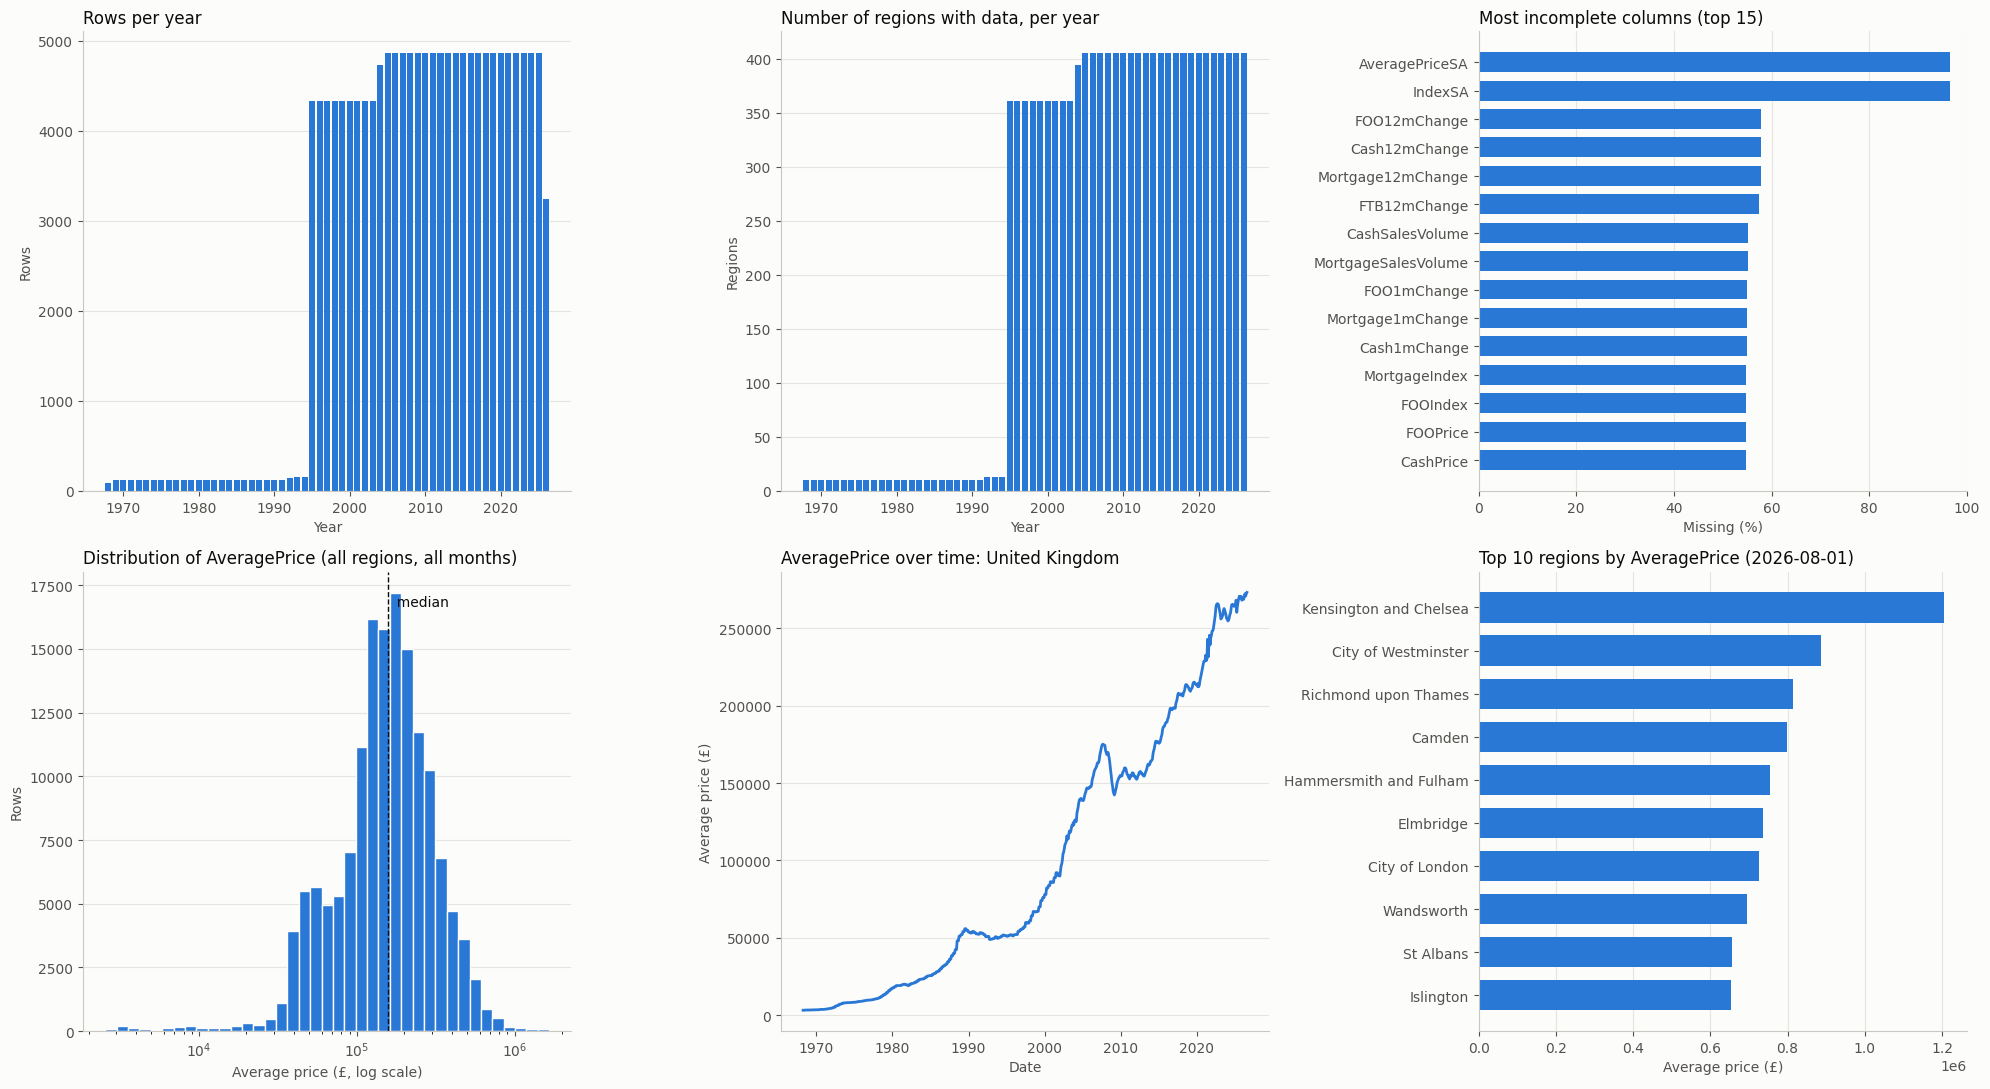

In [22]:
BLUE, BG, INK, MUTED, GRID = "#2a78d6", "#fcfcfb", "#0b0b0b", "#52514e", "#e5e4e0"
 
def style(ax, title, xlabel, ylabel, grid_axis="y"):
    ax.set_facecolor(BG)
    ax.set_title(title, loc="left", color=INK, fontsize=12)
    ax.set_xlabel(xlabel, color=MUTED)
    ax.set_ylabel(ylabel, color=MUTED)
    ax.tick_params(colors=MUTED)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#c8c7c1")
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
 
fig, axes = plt.subplots(2, 3, figsize=(20, 11), facecolor=BG)
 
# a) Rows per year
ax = axes[0, 0]
ax.bar(year_list, year_counts, width=0.8, color=BLUE)
style(ax, "Rows per year", "Year", "Rows")

# b) Regions reporting per year
ax = axes[0, 1]
regions_per_year = [len(np.unique(data["RegionName"][years == y])) for y in year_list]
ax.bar(year_list, regions_per_year, width=0.8, color=BLUE)
style(ax, "Number of regions with data, per year", "Year", "Regions")
 
# c) Missing values, top 15 columns
ax = axes[0, 2]
top = order[:15][::-1]
ax.barh([num_cols[i] for i in top], missing_pct[top], height=0.7, color=BLUE)
ax.set_xlim(0, 100)
style(ax, "Most incomplete columns (top 15)", "Missing (%)", "", grid_axis="x")
 
# d) Distribution of average price
ax = axes[1, 0]
price = data["AveragePrice"][~np.isnan(data["AveragePrice"])]
ax.hist(price, bins=np.logspace(np.log10(price.min()), np.log10(price.max()), 40),
        color=BLUE, edgecolor=BG, linewidth=1)
ax.set_xscale("log")
ax.axvline(statistics.median(price.tolist()), color=INK, linewidth=1, linestyle="--")
ax.text(statistics.median(price.tolist()), ax.get_ylim()[1] * 0.95, "  median", color=INK, va="top")
style(ax, "Distribution of AveragePrice (all regions, all months)", "Average price (£, log scale)", "Rows")
 
# e) Average price over time for one headline region
ax = axes[1, 1]
headline = "United Kingdom" if "United Kingdom" in regions else regions[np.argmax(region_counts)]
m = data["RegionName"] == headline
o = np.argsort(data["Date"][m])
ax.plot(data["Date"][m][o], data["AveragePrice"][m][o], color=BLUE, linewidth=2)
style(ax, f"AveragePrice over time: {headline}", "Date", "Average price (£)")
 
# f) Top 10 regions by latest average price
ax = axes[1, 2]
latest = data[data["Date"] == data["Date"].max()]
latest = latest[~np.isnan(latest["AveragePrice"])]
top10 = latest[np.argsort(latest["AveragePrice"])[-10:]]
ax.barh(top10["RegionName"], top10["AveragePrice"], height=0.7, color=BLUE)
style(ax, f"Top 10 regions by AveragePrice ({data['Date'].max()})", "Average price (£)", "", grid_axis="x")
 
plt.tight_layout()
plt.show()
 

# 4. Mortgage Rates - IUMBV34

IUMBV34 data represents the monthly average quoted interest rate for a 2-year fixed-rate mortgage at 75% loan-to-value (LTV)


In [17]:
file_path_iumbv34 = "../IUMBV34.csv"
file_path_iumbv42 = "../IUMBV42.csv"

iumbv34 = np.genfromtxt(
    fname = file_path_iumbv34,
    delimiter = ",",
    dtype = None,
    skip_header = 1,
    names = ["Date","Rate2y"],
    encoding = "utf-8"
)



# print(iumbv34[:5])
# print(iumbv42[:)
months = {
    "Jan": "01", "Feb": "02", "Mar": "03",
    "Apr": "04", "May": "05", "Jun": "06",
    "Jul": "07", "Aug": "08", "Sep": "09",
    "Oct": "10", "Nov": "11", "Dec": "12"
}
formatted_dates = []

for d in iumbv34["Date"]:
    parts = d.split()
    day = parts[0]
    month = months[parts[1]]
    year = parts[2]

    new_date = f"{year}-{month}-{day}"
    formatted_dates.append(new_date)

formatted_dates = np.array(formatted_dates, dtype="datetime64[D]")

# Create a new array with the correct data types
iumbv34_clean = np.empty(
    len(iumbv34),
    dtype=[
        ("Date", "datetime64[D]"),
        ("Rate2y", "f8")
    ]
)

# Assign the values
iumbv34_clean["Date"] = formatted_dates
iumbv34_clean["Rate2y"] = iumbv34["Rate2y"]

# Replace the original array
iumbv34 = iumbv34_clean


print("=== OVERVIEW IUMBV34 ===")
print("Rows         :", iumbv34.shape[0])
print("Date range   :", iumbv34["Date"].min(), "to", iumbv34["Date"].max())

print("=== DATA PREVIEW ===")
print(iumbv34[:5])

=== OVERVIEW IUMBV34 ===
Rows         : 380
Date range   : 1995-01-31 to 2026-08-31
=== DATA PREVIEW ===
[('1995-01-31', 8.13) ('1995-02-28', 8.38) ('1995-03-31', 8.08)
 ('1995-04-30', 8.29) ('1995-05-31', 8.22)]


In [18]:
iumbv42 = np.genfromtxt(
    fname = file_path_iumbv42,
    delimiter = ",",
    dtype = None,
    skip_header = 1,
    names = ["Date", "Rate5y"],
    encoding = "utf-8"
)
# print(iumbv42[:5])

# since the data is all 2005 + 
def add_century(s):
    d,m,y = s.strip('"').split()
    return f"20{y}-{months[m]}-{d.zfill(2)}"

formatted_dates = []

for d in iumbv42["Date"]:
    formatted_dates.append(add_century(d))

# Create the clean structured array
iumbv42_clean = np.empty(
    iumbv42.shape[0],
    dtype = [("Date", "datetime64[D]"), ("Rate5y", "f8")]
)

# Assign the values
iumbv42_clean["Date"] = formatted_dates
iumbv42_clean["Rate5y"] = np.char.strip(iumbv42["Rate5y"], '"').astype(float)

# Replace the original array
iumbv42 = iumbv42_clean


print("=== OVERVIEW IUMBV42 ===")
print("Rows         :", iumbv42.shape[0])
print("Date range   :", iumbv42["Date"].min(), "to", iumbv42["Date"].max())

print("=== DATA PREVIEW ===")
print(iumbv42[:5])

=== OVERVIEW IUMBV42 ===
Rows         : 262
Date range   : 2005-01-31 to 2026-10-31
=== DATA PREVIEW ===
[('2026-10-31', 5.19) ('2026-09-30', 4.98) ('2026-08-31', 4.78)
 ('2026-07-31', 4.58) ('2026-06-30', 4.62)]


In [19]:
# Find the common dates and their positions in each array
common_dates, idx_rate2y, idx_rate5y = np.intersect1d(
    iumbv34["Date"], iumbv42["Date"], return_indices = True
)

# Create the combined structured array
rates = np.empty(
    common_dates.shape[0],
    dtype = [("Date", "datetime64[D]"), ("Rate2y", "f8"), ("Rate5y", "f8")]
)

# Assign the values
rates["Date"] = common_dates
rates["Rate2y"] = iumbv34["Rate2y"][idx_rate2y]
rates["Rate5y"] = iumbv42["Rate5y"][idx_rate5y]


print("=== OVERVIEW RATES ===")
print("Rows         :", rates.shape[0])
print("Date range   :", rates["Date"].min(), "to", rates["Date"].max())

print("=== DATA PREVIEW ===")
print(rates[:5])

=== OVERVIEW RATES ===
Rows         : 260
Date range   : 2005-01-31 to 2026-08-31
=== DATA PREVIEW ===
[('2005-01-31', 4.99, 5.2 ) ('2005-02-28', 5.07, 5.25)
 ('2005-03-31', 5.2 , 5.28) ('2005-04-30', 5.16, 5.23)
 ('2005-05-31', 4.91, 5.05)]
